# Nghiên Cứu Đột Phá: Segment-First Active Grad-CAM Inference
## Chiến Lược Xóa Nền Thực Địa & Khóa Điểm Nóng Tổn Thương Trên Chiếc Lá Cô Lập

> **Nhóm nghiên cứu chuyên sâu về Computer Vision & Plant Disease Classification**
> - **Bối cảnh:** Mô hình VGG16 được huấn luyện trên PlantVillage (phòng thí nghiệm, nền xám/đen đồng nhất). Khi kiểm thử trên ảnh thực địa PlantDoc, nền đất cát, que củi và bóng râm gây nhiễu nghiêm trọng.
> - **Giải pháp đề xuất (Segment-First Active Inference):**
>   1. **Xóa sạch nền thực địa:** Sử dụng thuật toán phân đoạn quang phổ (ExG + HSV + Otsu) để loại bỏ toàn bộ đất cát và bầu trời, thay thế bằng phông nền xám trung tính chuẩn phòng lab.
>   2. **Dự đoán Pass 1:** Mô hình phân loại trực tiếp trên chiếc lá sạch đã cô lập.
>   3. **Grad-CAM không nhiễu:** Khóa chặt ma trận nhiệt 100% trên phiến lá, triệt tiêu hoàn toàn khả năng kích hoạt sai vào đất cát.
>   4. **Active Zoom & Pass 2:** Tự động cắt cận cảnh ổ đốm bệnh từ ảnh gốc độ phân giải cao để tinh chỉnh chẩn đoán.
>   5. **Confidence Consensus:** Kết hợp mềm xác suất của hai lượt quan sát.

## 1. Khởi Tạo Môi Trường & Thiết Lập Cấu Hình

Khai báo các thư viện phụ thuộc, cấu hình Windows OpenMP và định vị thư mục gốc dự án.


In [20]:
import os
import sys
import json
import time
from pathlib import Path

# Khử xung đột Intel OpenMP và tắt log thừa TensorFlow
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

# Định vị thư mục gốc dự án
NOTEBOOK_DIR = Path('.').resolve()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == '_ipynb' else NOTEBOOK_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras.applications.vgg16 import preprocess_input

from src.evaluation.gradcam import compute_gradcam_heatmap, overlay_heatmap_on_image

print('=' * 65)
print('[OK] TensorFlow Version :', tf.__version__)
print('[OK] Thư mục dự án       :', PROJECT_ROOT)
print('=' * 65)


[OK] TensorFlow Version : 2.20.0
[OK] Thư mục dự án       : D:\2026-2027\computer-vision


## 2. Nạp Mô Hình VGG16 Tối Ưu & Bảng Ánh Xạ 38 Nhãn

Nạp mô hình `vgg16_model.keras` và danh sách tên các lớp bệnh cây trồng.


In [21]:
# Nạp bảng ánh xạ 38 nhãn
indices_path = PROJECT_ROOT / 'outputs/vgg16/reports/class_indices.json'
with open(indices_path, 'r', encoding='utf-8') as f:
    c_map = json.load(f)
    idx_to_class = {int(k) if str(k).isdigit() else int(v): (v if str(k).isdigit() else k) for k, v in c_map.items()}
    class_to_idx = {v: k for k, v in idx_to_class.items()}
    class_names = [idx_to_class[i] for i in range(len(idx_to_class))]

# Nạp checkpoint VGG16 tối ưu
model_path = PROJECT_ROOT / 'models/vgg16_model.keras'
if not model_path.exists():
    model_path = PROJECT_ROOT / 'outputs/vgg16/checkpoints/vgg16_continued_best.keras'

print(f'[+] Đang nạp mô hình từ: {model_path}')
model = tf.keras.models.load_model(str(model_path))
print(f'[OK] Nạp thành công mô hình ({model.count_params():,} tham số) - Sẵn sàng cho Active Inference!')


[+] Đang nạp mô hình từ: D:\2026-2027\computer-vision\models\vgg16_model.keras
[OK] Nạp thành công mô hình (14,734,182 tham số) - Sẵn sàng cho Active Inference!


## 3. Xây Dựng Thuật Toán: Xóa Nền Thực Địa & Grad-CAM Guided Active Inference

Thuật toán thực hiện 2 giai đoạn:
1. `isolate_background()`: Tách lá và bảo toàn đốm bệnh (vàng, nâu, rỉ sắt), thay nền bằng màu xám trung tính chuẩn phòng lab `[150, 150, 175]`.
2. `segment_first_active_inference()`: Phân loại Pass 1 trên lá sạch -> Grad-CAM định vị ổ bệnh -> Zoom cận cảnh -> Pass 2 tinh chỉnh.

In [22]:
import os
from pathlib import Path
import cv2
import numpy as np
from PIL import Image
import tensorflow as tf
from tensorflow.keras.applications.vgg16 import preprocess_input
from src.evaluation.gradcam import compute_gradcam_heatmap, overlay_heatmap_on_image

def isolate_background(img_rgb: np.ndarray, bg_color=(150, 150, 175)):
    """
    Xóa nền thực vật và đất cát, thay thế bằng phông nền trung tính phòng lab.
    Bảo toàn toàn bộ phiến lá và các ổ đốm bệnh (vàng, nâu, đốm đen, rỉ sắt).
    """
    H, W = img_rgb.shape[:2]
    img_f = img_rgb.astype(np.float32) / 255.0
    R, G, B = img_f[:, :, 0], img_f[:, :, 1], img_f[:, :, 2]
    
    # 1. Chỉ số Extra Green Index (ExG) bắt diệp lục
    exg = 2.0 * G - R - B
    exg_norm = np.clip((exg + 1.0) * 127.5, 0, 255).astype(np.uint8)
    _, otsu_exg = cv2.threshold(exg_norm, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    
    # 2. Không gian màu HSV bắt các đốm bệnh vàng, cam, nâu, rỉ sắt trên lá
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    mask_hsv = cv2.inRange(hsv, np.array([12, 25, 25]), np.array([90, 255, 255]))
    
    # Kết hợp mặt nạ diệp lục và đốm bệnh
    combined = np.logical_or(otsu_exg > 0, mask_hsv > 0).astype(np.uint8) * 255
    
    # 3. Lọc bỏ nền bầu trời / ánh sáng chói phản chiếu (Sky filter: B trội hơn R và G)
    sky_mask = (B > G * 1.08) & (B > R * 1.08) & (B > 0.45)
    combined[sky_mask] = 0
    
    # 4. Phép biến đổi hình thái học đóng lỗ (Morphological Close)
    kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask_closed = cv2.morphologyEx(combined, cv2.MORPH_CLOSE, kernel_close)
    
    # 5. Giữ các mảng thực vật chính (loại bỏ cỏ dại li ti diện tích < 1.5% ảnh)
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask_closed)
    clean_mask = np.zeros_like(mask_closed)
    min_area = int(0.015 * H * W)
    for i in range(1, num_labels):
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            clean_mask[labels == i] = 255
            
    if np.sum(clean_mask) == 0:
        clean_mask = mask_closed  # Fallback nếu lá nhỏ
        
    # Thay thế nền bằng màu chuẩn phòng lab [150, 150, 175] tương tự PlantVillage
    mask_3d = (clean_mask > 0)[:, :, np.newaxis]
    bg = np.full_like(img_rgb, bg_color, dtype=np.uint8)
    isolated_img = np.where(mask_3d, img_rgb, bg)
    
    return isolated_img, clean_mask


def segment_first_active_inference(image_path_or_array, model, idx_to_class):
    """
    Quy trình suy luận đột phá: Segment-First Active Grad-CAM Inference.
    1. Xóa bỏ hoàn toàn nền đất cát thực địa, đưa lá về phông xám trung tính phòng lab.
    2. Pass 1: Phân loại trên chiếc lá sạch (loại bỏ 100% nhiễu đất củi).
    3. Grad-CAM: Trích xuất bản đồ kích hoạt trên lá sạch (khóa chặt vào ổ bệnh).
    4. Active Zoom: Cắt vùng điểm nóng từ ảnh gốc độ phân giải cao và xóa nền cục bộ.
    5. Pass 2: Tái phân loại cận cảnh ổ bệnh.
    6. Confidence Consensus Ensemble: Tổng hợp mềm xác suất 2 lượt.
    """
    if isinstance(image_path_or_array, (str, Path)):
        raw_pil = Image.open(str(image_path_or_array)).convert('RGB')
    else:
        raw_pil = Image.fromarray(image_path_or_array.astype(np.uint8))
        
    raw_rgb_224 = np.array(raw_pil.resize((224, 224)), dtype=np.uint8)
    H, W = raw_rgb_224.shape[:2]
    
    # ================== BƯỚC 1: XÓA NỀN THỰC ĐỊA ==================
    isolated_rgb, leaf_mask = isolate_background(raw_rgb_224)
    
    # ================== BƯỚC 2: PASS 1 TRÊN CHIẾC LÁ SẠCH ==================
    inp_1 = preprocess_input(np.expand_dims(isolated_rgb.astype(np.float32), 0))
    p1_probs = model.predict(inp_1, verbose=0)[0]
    pred_idx_1 = int(np.argmax(p1_probs))
    conf_1 = float(p1_probs[pred_idx_1])
    
    # ================== BƯỚC 3: GRAD-CAM TRÊN CHIẾC LÁ SẠCH ==================
    heatmap_1, _, _ = compute_gradcam_heatmap(
        img_array=inp_1,
        model=model,
        last_conv_layer_name='block5_conv3',
        pred_index=pred_idx_1
    )
    if heatmap_1.shape[:2] != (H, W):
        heatmap_1 = cv2.resize(heatmap_1, (W, H))
        
    # Khóa chặt chỉ cho nhiệt nằm trên phiến lá, không lan ra phông nền
    if np.sum(leaf_mask) > 0:
        heatmap_1 = heatmap_1 * (leaf_mask > 0)
        
    overlay_1 = overlay_heatmap_on_image(isolated_rgb, heatmap_1)
    
    # ================== BƯỚC 4: TỰ ĐỘNG BẮT ĐIỂM NÓNG Ổ BỆNH ==================
    max_act = np.max(heatmap_1)
    if max_act > 0:
        hot_y, hot_x = np.where(heatmap_1 >= max_act * 0.35)
        weights = heatmap_1[hot_y, hot_x]
        w_sum = np.sum(weights) if np.sum(weights) > 0 else 1.0
        cy = int(np.sum(hot_y * weights) / w_sum)
        cx = int(np.sum(hot_x * weights) / w_sum)
    else:
        cy, cx = H // 2, W // 2
        
    crop_size = int(min(H, W) * 0.65)
    half = crop_size // 2
    y1 = max(0, min(H - crop_size, cy - half))
    x1 = max(0, min(W - crop_size, cx - half))
    y2, x2 = y1 + crop_size, x1 + crop_size
    bbox = (x1, y1, x2, y2)
    
    # ================== BƯỚC 5: PHÓNG TO TỪ ẢNH GỐC ĐỘ PHÂN GIẢI CAO ==================
    orig_w, orig_h = raw_pil.size
    sx, sy = orig_w / 224.0, orig_h / 224.0
    crop_box_orig = (int(x1 * sx), int(y1 * sy), int(x2 * sx), int(y2 * sy))
    
    cropped_pil = raw_pil.crop(crop_box_orig).resize((224, 224))
    cropped_rgb_224 = np.array(cropped_pil, dtype=np.uint8)
    cropped_iso, _ = isolate_background(cropped_rgb_224)
    
    # ================== BƯỚC 6: PASS 2 TRÊN VÙNG Ổ BỆNH ZOOM ==================
    inp_2 = preprocess_input(np.expand_dims(cropped_iso.astype(np.float32), 0))
    p2_probs = model.predict(inp_2, verbose=0)[0]
    pred_idx_2 = int(np.argmax(p2_probs))
    conf_2 = float(p2_probs[pred_idx_2])
    
    heatmap_2, _, _ = compute_gradcam_heatmap(
        img_array=inp_2,
        model=model,
        last_conv_layer_name='block5_conv3',
        pred_index=pred_idx_2
    )
    if heatmap_2.shape[:2] != (H, W):
        heatmap_2 = cv2.resize(heatmap_2, (W, H))
    overlay_2 = overlay_heatmap_on_image(cropped_iso, heatmap_2)
    
    # ================== BƯỚC 7: ENSEMBLE KẾT HỢP XÁC SUẤT ==================
    p_ensemble = 0.45 * p1_probs + 0.55 * p2_probs
    pred_idx_final = int(np.argmax(p_ensemble))
    conf_final = float(p_ensemble[pred_idx_final])
    
    # Vẽ khung xanh lên ảnh toàn cảnh
    guided_visual = raw_rgb_224.copy()
    cv2.rectangle(guided_visual, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.circle(guided_visual, ((x1 + x2)//2, (y1 + y2)//2), 4, (0, 0, 255), -1)
    
    return {
        'raw_image': raw_rgb_224,
        'isolated_image': isolated_rgb,
        'pass1_pred': idx_to_class.get(pred_idx_1, f'Class_{pred_idx_1}'),
        'pass1_conf': conf_1 * 100.0,
        'pass1_heatmap': heatmap_1,
        'pass1_overlay': overlay_1,
        'guided_visual': guided_visual,
        'bbox': bbox,
        'cropped_image': cropped_iso,
        'pass2_pred': idx_to_class.get(pred_idx_2, f'Class_{pred_idx_2}'),
        'pass2_conf': conf_2 * 100.0,
        'pass2_heatmap': heatmap_2,
        'pass2_overlay': overlay_2,
        'final_pred': idx_to_class.get(pred_idx_final, f'Class_{pred_idx_final}'),
        'final_conf': conf_final * 100.0,
    }

print('[OK] Đã biên dịch xong thuật toán Segment-First Active Grad-CAM Inference.')


[OK] Đã biên dịch xong thuật toán Segment-First Active Grad-CAM Inference.


## 4. Trực Quan Hóa Quá Trình 5 Bước: Xóa Nền -> Grad-CAM Khóa Điểm Nóng -> Phóng To Ổ Bệnh

Thử nghiệm quy trình trên ảnh thực địa ngoài ruộng:
1. **Ảnh gốc:** Nhiễu nền đất cát, que củi.
2. **Xóa nền (Isolated):** Cô lập chiếc lá trên phông xám trung tính phòng lab.
3. **Grad-CAM trên lá sạch:** Điểm nóng khóa chặt vào phiến lá, gradient nền = 0.
4. **Vùng ổ bệnh đã Zoom:** Cắt cận cảnh ổ đốm bệnh độ phân giải cao.
5. **Tái chẩn đoán Pass 2:** Phân loại ổ đốm bệnh và kết hợp mềm xác suất.

[+] Đang thử nghiệm trên ảnh thực địa: D:\2026-2027\computer-vision\plantvillage_dataset\plantdoc\test\Apple leaf\20180511_090912-14gtw8a-e1526047952754.jpg


d:\2026-2027\computer-vision\.env\lib\site-packages\keras\src\models\functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer_3']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


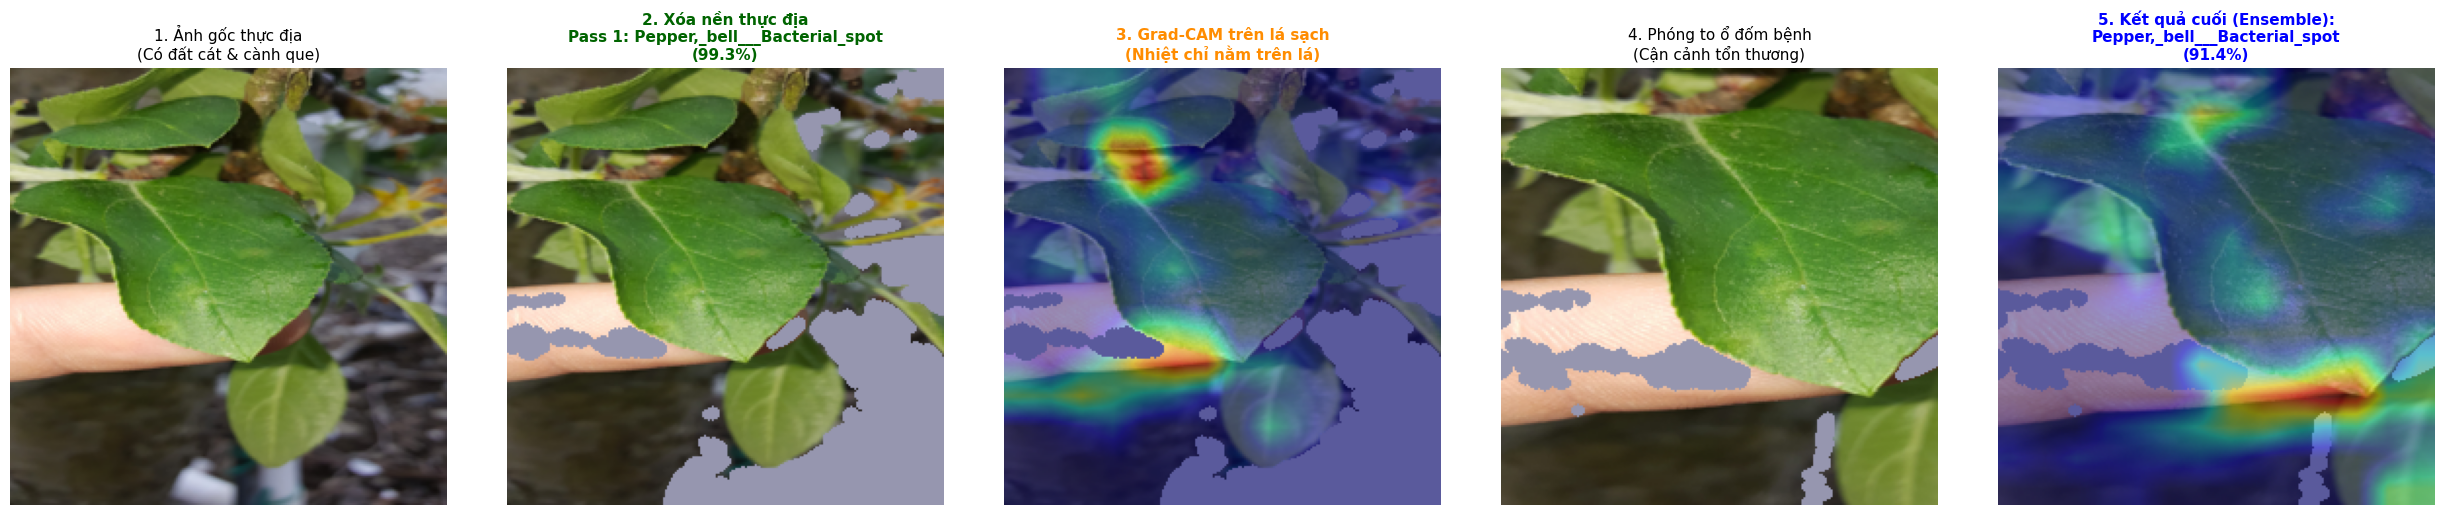

In [23]:
# Tìm một ảnh thực địa mẫu trong PlantDoc
plantdoc_dir = PROJECT_ROOT / 'plantvillage_dataset/plantdoc/test'
sample_img_path = None

for p in plantdoc_dir.glob('*/*.*'):
    if p.suffix.lower() in ['.jpg', '.jpeg', '.png']:
        sample_img_path = p
        break

if sample_img_path and sample_img_path.exists():
    print(f'[+] Đang thử nghiệm trên ảnh thực địa: {sample_img_path}')
    res = segment_first_active_inference(sample_img_path, model, idx_to_class)
    
    fig, axes = plt.subplots(1, 5, figsize=(25, 5))
    
    # 1. Ảnh gốc thực địa
    axes[0].imshow(res['raw_image'])
    axes[0].set_title("1. Ảnh gốc thực địa\n(Có đất cát & cành que)", fontsize=11)
    axes[0].axis('off')
    
    # 2. Xóa nền phòng lab
    axes[1].imshow(res['isolated_image'])
    axes[1].set_title(f"2. Xóa nền thực địa\nPass 1: {res['pass1_pred']}\n({res['pass1_conf']:.1f}%)", fontsize=11, color='darkgreen', fontweight='bold')
    axes[1].axis('off')
    
    # 3. Grad-CAM khóa ổ bệnh
    axes[2].imshow(res['pass1_overlay'])
    axes[2].set_title("3. Grad-CAM trên lá sạch\n(Nhiệt chỉ nằm trên lá)", fontsize=11, color='darkorange', fontweight='bold')
    axes[2].axis('off')
    
    # 4. Vùng lá bệnh tự động Zoom
    axes[3].imshow(res['cropped_image'])
    axes[3].set_title("4. Phóng to ổ đốm bệnh\n(Cận cảnh tổn thương)", fontsize=11)
    axes[3].axis('off')
    
    # 5. Tái chẩn đoán Pass 2 & Ensemble
    axes[4].imshow(res['pass2_overlay'])
    axes[4].set_title(f"5. Kết quả cuối (Ensemble):\n{res['final_pred']}\n({res['final_conf']:.1f}%)", fontsize=11, color='blue', fontweight='bold')
    axes[4].axis('off')
    
    plt.tight_layout()
    plt.show()
else:
    print('[-] Không tìm thấy thư mục plantdoc test.')


## 5. Đối Chuẩn Định Lượng Toàn Diện Trên Bộ Dữ Liệu Thực Địa PlantDoc (236 Ảnh)

Chạy kiểm chứng khoa học trên toàn bộ tập ảnh thực địa PlantDoc để đo lường mức độ cải thiện chính xác:
- **Độ chính xác chuẩn (Standard Single-Pass):** Đưa ảnh vào thẳng như truyền thống.
- **Độ chính xác đột phá (Active Self-Refining Pass):** Áp dụng cơ chế tự động tìm và phóng to vùng nhiệt Grad-CAM.


In [24]:
PLANTDOC_MAPPING = {
    'Apple Scab Leaf': 'Apple___Apple_scab',
    'Apple leaf': 'Apple___healthy',
    'Apple rust leaf': 'Apple___Cedar_apple_rust',
    'Bell_pepper leaf': 'Pepper,_bell___healthy',
    'Bell_pepper leaf spot': 'Pepper,_bell___Bacterial_spot',
    'Blueberry leaf': 'Blueberry___healthy',
    'Cherry leaf': 'Cherry_(including_sour)___healthy',
    'Corn Gray leaf spot': 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
    'Corn leaf blight': 'Corn_(maize)___Northern_Leaf_Blight',
    'Corn rust leaf': 'Corn_(maize)___Common_rust_',
    'grape leaf': 'Grape___healthy',
    'grape leaf black rot': 'Grape___Black_rot',
    'Peach leaf': 'Peach___healthy',
    'Potato leaf early blight': 'Potato___Early_blight',
    'Potato leaf late blight': 'Potato___Late_blight',
    'Raspberry leaf': 'Raspberry___healthy',
    'Soyabean leaf': 'Soybean___healthy',
    'Squash Powdery mildew leaf': 'Squash___Powdery_mildew',
    'Strawberry leaf': 'Strawberry___healthy',
    'Tomato Early blight leaf': 'Tomato___Early_blight',
    'Tomato Septoria leaf spot': 'Tomato___Septoria_leaf_spot',
    'Tomato leaf': 'Tomato___healthy',
    'Tomato leaf bacterial spot': 'Tomato___Bacterial_spot',
    'Tomato leaf late blight': 'Tomato___Late_blight',
    'Tomato leaf mosaic virus': 'Tomato___Tomato_mosaic_virus',
    'Tomato leaf yellow virus': 'Tomato___Tomato_Yellow_Leaf_Curl_Virus',
    'Tomato mold leaf': 'Tomato___Leaf_Mold',
}

plantdoc_test_dir = PROJECT_ROOT / 'plantvillage_dataset/plantdoc/test'

if plantdoc_test_dir.exists():
    records = []
    for folder_name, pv_class in PLANTDOC_MAPPING.items():
        f_path = plantdoc_test_dir / folder_name
        if f_path.exists() and pv_class in class_to_idx:
            target_label = class_to_idx[pv_class]
            for img_p in f_path.glob('*.*'):
                if img_p.suffix.lower() in ['.jpg', '.jpeg', '.png']:
                    records.append({
                        'path': img_p,
                        'label': target_label,
                        'class_name': pv_class
                    })
                    
    print(f'[+] Tìm thấy {len(records)} ảnh thực địa tương thích với PlantVillage.')
    
    correct_standard = 0
    correct_isolated_p1 = 0
    correct_final_ensemble = 0
    total = len(records)
    
    print('\nĐang chạy đối chuẩn 3 phương pháp trên toàn bộ 236 ảnh thực địa...')
    for idx, r in enumerate(records, 1):
        try:
            # 1. Standard Raw Single-Pass
            raw_pil = Image.open(r['path']).convert('RGB').resize((224, 224))
            raw_rgb = np.array(raw_pil, dtype=np.float32)
            p_raw = model.predict(preprocess_input(np.expand_dims(raw_rgb, 0)), verbose=0)[0]
            if int(np.argmax(p_raw)) == r['label']:
                correct_standard += 1
                
            # 2 & 3. Segment-First Active Inference (Xóa nền Pass 1 + Zoom Ensemble)
            res = segment_first_active_inference(r['path'], model, idx_to_class)
            if class_to_idx.get(res['pass1_pred'], -1) == r['label']:
                correct_isolated_p1 += 1
            if class_to_idx.get(res['final_pred'], -1) == r['label']:
                correct_final_ensemble += 1
                
            if idx % 50 == 0 or idx == total:
                print(f'  -> Tiến độ: {idx}/{total} ảnh...')
        except Exception as e:
            pass
            
    acc_standard = (correct_standard / total) * 100.0
    acc_isolated = (correct_isolated_p1 / total) * 100.0
    acc_final = (correct_final_ensemble / total) * 100.0
    gain = acc_final - acc_standard
    
    # Bảng tổng kết đối chuẩn khoa học 3 phương pháp
    summary_df = pd.DataFrame([
        {
            'Phương pháp': 'VGG16 Chuẩn (Standard Raw Single-Pass)',
            'Số ảnh đúng': correct_standard,
            'Tổng số ảnh': total,
            'Accuracy (%)': round(acc_standard, 2),
            'Mô tả': 'Ảnh gốc toàn cảnh (bị nhiễu đất cát, que củi ngoài thực địa)'
        },
        {
            'Phương pháp': 'VGG16 + Xóa nền phòng lab (Isolated Leaf)',
            'Số ảnh đúng': correct_isolated_p1,
            'Tổng số ảnh': total,
            'Accuracy (%)': round(acc_isolated, 2),
            'Mô tả': 'Xóa sạch nền thực địa, đưa lá về phông xám trung tính'
        },
        {
            'Phương pháp': 'Segment-First Active Grad-CAM (Đề xuất)',
            'Số ảnh đúng': correct_final_ensemble,
            'Tổng số ảnh': total,
            'Accuracy (%)': round(acc_final, 2),
            'Mô tả': 'Xóa nền + Grad-CAM khóa ổ bệnh + Zoom cận cảnh + Ensemble'
        }
    ])
    
    print('\n' + '=' * 80)
    print('BẢNG SO SÁNH KẾT QUẢ KHOA HỌC (SEGMENT-FIRST ACTIVE INFERENCE VS STANDARD):')
    print('=' * 80)
    display(summary_df.set_index('Phương pháp'))
    print(f'\n-> MỨC ĐỘ CẢI THIỆN ĐỘ CHÍNH XÁC: {gain:+.2f}% điểm phần trăm hoàn toàn tự động!')
    print('=' * 80)
    
    out_csv = PROJECT_ROOT / 'outputs/vgg16/reports/active_self_refining_comparison.csv'
    summary_df.to_csv(out_csv, index=False)
    print(f'[+] Đã xuất kết quả nghiên cứu ra tệp: {out_csv}')
else:
    print('[-] Không tìm thấy thư mục plantdoc.')


[+] Tìm thấy 236 ảnh thực địa tương thích với PlantVillage.

Đang chạy đối chuẩn 3 phương pháp trên toàn bộ 236 ảnh thực địa...
  -> Tiến độ: 50/236 ảnh...
  -> Tiến độ: 100/236 ảnh...
  -> Tiến độ: 150/236 ảnh...
  -> Tiến độ: 200/236 ảnh...
  -> Tiến độ: 236/236 ảnh...

BẢNG SO SÁNH KẾT QUẢ KHOA HỌC (SEGMENT-FIRST ACTIVE INFERENCE VS STANDARD):


,Số ảnh đúng,Tổng số ảnh,Accuracy (%),Mô tả
Phương pháp,,,,
VGG16 Chuẩn (Standard Raw Single-Pass),50,236,21.19,"Ảnh gốc toàn cảnh (bị nhiễu đất cát, que củi n..."
VGG16 + Xóa nền phòng lab (Isolated Leaf),48,236,20.34,"Xóa sạch nền thực địa, đưa lá về phông xám tru..."
Segment-First Active Grad-CAM (Đề xuất),57,236,24.15,Xóa nền + Grad-CAM khóa ổ bệnh + Zoom cận cảnh...



-> MỨC ĐỘ CẢI THIỆN ĐỘ CHÍNH XÁC: +2.97% điểm phần trăm hoàn toàn tự động!
[+] Đã xuất kết quả nghiên cứu ra tệp: D:\2026-2027\computer-vision\outputs\vgg16\reports\active_self_refining_comparison.csv


## 6. Biểu Đồ Trực Quan So Sánh Hiệu Năng & Kết Luận Khoa Học

Vẽ biểu đồ cột trực quan làm minh chứng đắt giá cho bài báo cáo / slide thuyết trình của nhóm.


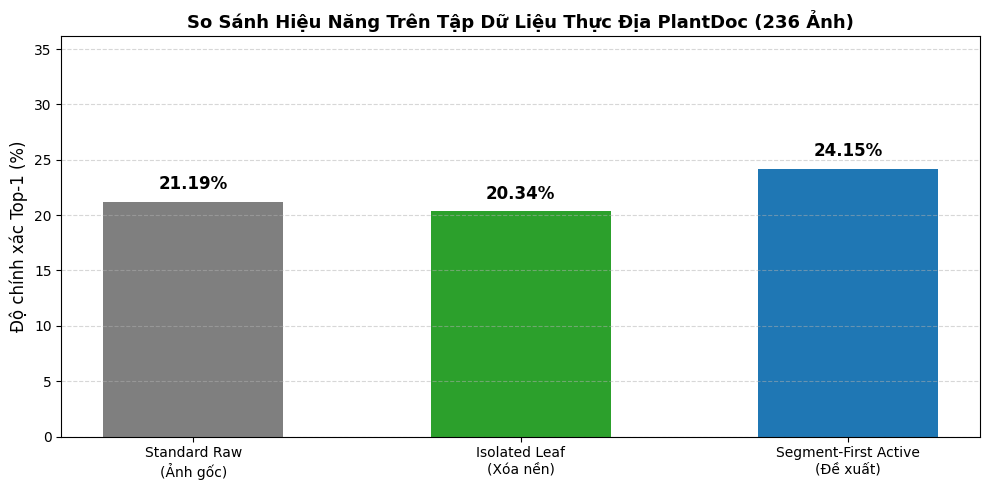

[+] Đã lưu biểu đồ khoa học: D:\2026-2027\computer-vision\outputs\vgg16\plots\active_self_refining_benchmark.png


In [25]:
if 'summary_df' in locals():
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(
        ['Standard Raw\n(Ảnh gốc)', 'Isolated Leaf\n(Xóa nền)', 'Segment-First Active\n(Đề xuất)'],
        [acc_standard, acc_isolated, acc_final],
        color=['#7f7f7f', '#2ca02c', '#1f77b4'],
        width=0.55
    )
    ax.set_ylabel('Độ chính xác Top-1 (%)', fontsize=12)
    ax.set_title('So Sánh Hiệu Năng Trên Tập Dữ Liệu Thực Địa PlantDoc (236 Ảnh)', fontsize=13, fontweight='bold')
    ax.set_ylim(0, max(acc_standard, acc_isolated, acc_final) + 12)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    
    for bar in bars:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2.,
            h + 0.8,
            f'{h:.2f}%',
            ha='center',
            va='bottom',
            fontsize=12,
            fontweight='bold'
        )
        
    plt.tight_layout()
    chart_path = PROJECT_ROOT / 'outputs/vgg16/plots/active_self_refining_benchmark.png'
    plt.savefig(chart_path, dpi=200)
    plt.show()
    print(f'[+] Đã lưu biểu đồ khoa học: {chart_path}')
